<a href="https://colab.research.google.com/github/bgeethagayathri2-del/Movie-review-sentiment-analysis/blob/main/Sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.


Shape: (2000, 3)
sentiment
neg    1000
pos    1000
Name: count, dtype: int64


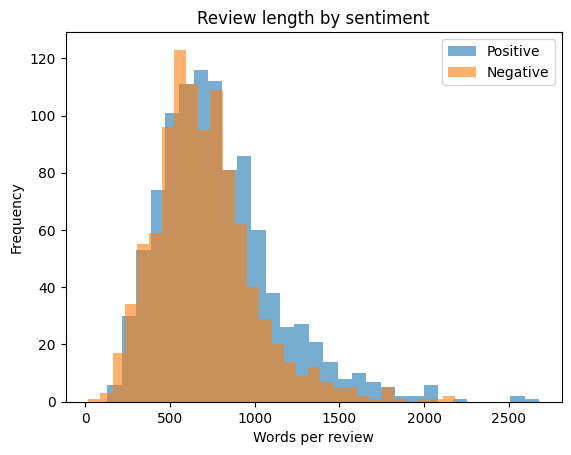

Logistic Regression accuracy: 0.812
Linear SVM accuracy: 0.833
              precision    recall  f1-score   support

    Negative       0.83      0.79      0.81       200
    Positive       0.80      0.84      0.82       200

    accuracy                           0.81       400
   macro avg       0.81      0.81      0.81       400
weighted avg       0.81      0.81      0.81       400



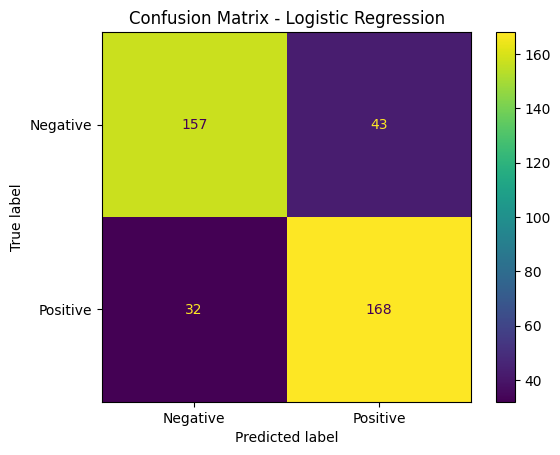

Cross-validation accuracy: 0.829
Most negative words: ['bad', 'worst', 'plot', 'movie', 'boring', 'supposed', 'script', 'harry', 'stupid', 'waste']
Most positive words: ['great', 'life', 'war', 'family', 'best', 'excellent', 'truman', 'world', 'perfect', 'mulan']
'An amazing film with brilliant acting and a wonderful story' -> POSITIVE
'A boring, predictable movie and a complete waste of time' -> NEGATIVE


In [1]:
# Movie Review Sentiment Analysis
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import movie_reviews
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Load 2,000 movie reviews (1,000 positive and 1,000 negative)
nltk.download("movie_reviews")
rows = [(movie_reviews.raw(fid), cat)
        for cat in movie_reviews.categories()
        for fid in movie_reviews.fileids(cat)]
df = pd.DataFrame(rows, columns=["review", "sentiment"])
df["label"] = df["sentiment"].map({"neg": 0, "pos": 1})
print("Shape:", df.shape)
print(df["sentiment"].value_counts())

# 2. Graph: review length (in words) for each sentiment
df["length"] = df["review"].str.split().str.len()
df[df["sentiment"] == "pos"]["length"].plot(kind="hist", bins=30, alpha=0.6, label="Positive")
df[df["sentiment"] == "neg"]["length"].plot(kind="hist", bins=30, alpha=0.6, label="Negative")
plt.xlabel("Words per review")
plt.title("Review length by sentiment")
plt.legend()
plt.show()

# 3. Split
X_train, X_test, y_train, y_test = train_test_split(
    df["review"], df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)

# 4. Turn text into numbers (single words and two-word phrases)
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                             min_df=3, max_features=20000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# 5. Train two models
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_vec, y_train)
svm = LinearSVC()
svm.fit(X_train_vec, y_train)

lr_pred = lr.predict(X_test_vec)
svm_pred = svm.predict(X_test_vec)
print("Logistic Regression accuracy:", round(accuracy_score(y_test, lr_pred), 3))
print("Linear SVM accuracy:", round(accuracy_score(y_test, svm_pred), 3))

# 6. Detailed report and confusion matrix
print(classification_report(y_test, lr_pred, target_names=["Negative", "Positive"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, lr_pred),
                       display_labels=["Negative", "Positive"]).plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# 7. Cross-validation (5 different splits, a fairer test)
pipe = make_pipeline(TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                                     min_df=3, max_features=20000),
                     LogisticRegression(max_iter=1000))
cv_scores = cross_val_score(pipe, df["review"], df["label"], cv=5)
print("Cross-validation accuracy:", round(cv_scores.mean(), 3))

# 8. Words that push a review towards positive or negative
words = vectorizer.get_feature_names_out()
order = lr.coef_[0].argsort()
print("Most negative words:", [words[i] for i in order[:10]])
print("Most positive words:", [words[i] for i in order[-10:][::-1]])

# 9. Try your own reviews
tests = [
    "An amazing film with brilliant acting and a wonderful story",
    "A boring, predictable movie and a complete waste of time"
]
for text, pred in zip(tests, lr.predict(vectorizer.transform(tests))):
    print(f"'{text}' -> {'POSITIVE' if pred == 1 else 'NEGATIVE'}")